# 응용 02 · 보간법별 축소와 확대

`02_interpolation.py`의 A02 구현과 실제 왕복 변환 결과를 확인합니다.

흐름: 같은 원본 읽기 → 세 보간법으로 80×60 축소 → 같은 보간법으로 320×240 확대 → PNG 저장 → 원본과 왕복 MSE 계산 → CSV 저장.

| 보간법 | 동작 |
|---|---|
| NEAREST | 가까운 원본 픽셀을 선택합니다. |
| LINEAR | 주변 픽셀을 선형 보간합니다. |
| AREA | 픽셀 영역 관계를 이용하며 일반적으로 축소에 사용합니다. |

`cv2.resize`의 크기 인자는 `(너비, 높이)`이며 NumPy shape 순서와 다릅니다. AREA도 명시적인 보간 방식입니다. 축소 후 확대해도 제거된 원본 정보가 복구되는 것은 아닙니다.

왕복 MSE는 모든 픽셀·채널에 대한 `(원본 - 확대 결과)²`의 평균입니다. 빼기 전에 float32로 변환해 uint8 연산의 순환을 피합니다. 이 수치는 해당 합성 이미지의 변환 오차이며 모델 성능이나 보간법의 일반적인 우열을 뜻하지 않습니다.

이 노트북은 실제 코드를 실행하고 결과를 표시합니다. 입력은 보존하고 실습 코드의 출력 파일은 다시 생성합니다. 프로젝트 `.venv` 등 `opencv-python`, `numpy`, `matplotlib`, `pandas`, `IPython`이 설치된 커널에서 위에서부터 실행하세요.

In [1]:
from pathlib import Path
import os
import pandas as pd
from IPython.display import display, Image

# 노트북 폴더 또는 프로젝트 내부에서 실행할 수 있도록 루트를 찾습니다.
notebook_start = Path.cwd().resolve()
project = next((p for p in [notebook_start, *notebook_start.parents]
                if (p / "20261104/02_응용/02_interpolation.py").is_file()), None)
if project is None:
    raise FileNotFoundError("프로젝트 내부에서 실행하세요.")
exercise = project / "20261104/02_응용"


## 1. 실습 코드 실행

현재 Python 파일의 코드를 사용합니다. 노트북에는 `__file__`이 없으므로 원본의 경로 준비 부분만 `exercise`로 바꿨습니다. TODO 구현과 출력 계산은 그대로입니다.

In [2]:
from pathlib import Path
import os
import cv2
import numpy as np

# 제공 코드: 어느 작업 폴더에서 실행해도 현재 파일 옆의 입력을 읽습니다.
# OpenCV에는 영문 상대 경로를 전달합니다. 원본 파일은 덮어쓰지 않습니다.
os.chdir(exercise)

import csv
import json
from time import perf_counter
Path("outputs").mkdir(exist_ok=True)

image = cv2.imread("data/scene.png")
rows = []
methods = (
    { "name": "nearest", "method": cv2.INTER_NEAREST }, # 인접한 기준으로 보간 / 명확하게 분리되어 있는 픽셀단위
    { "name": "linear", "method": cv2.INTER_LINEAR }, # 선형보간 / 수채화 느낌 확대
    { "name": "area", "method": cv2.INTER_AREA }, # 일반적인 확대 / 별도처리 안함
)
for item in methods:
    name = item["name"]
    method = item["method"]
    # >>> TODO A02
    # 현재 method를 사용해 (너비80, 높이60)으로 축소한 small을 만드세요.
    small = cv2.resize(image, (80, 60), interpolation=method)
    # <<< TODO A02
    large = cv2.resize(small, (320, 240), interpolation=method)
    cv2.imwrite(f"outputs/p02_{name}_small.png", small)
    cv2.imwrite(f"outputs/p02_{name}_large.png", large)
    # 동일 원본과 크기일 때만 오차를 비교합니다. float 변환으로 uint8 차이의 순환을 피합니다.
    mse = np.mean((image.astype(np.float32) - large.astype(np.float32)) ** 2)
    rows.append([name, small.shape[1], small.shape[0], round(float(mse), 4)])
with open("outputs/p02_interpolation.csv", "w", encoding="utf-8-sig", newline="") as f:
    w = csv.writer(f); w.writerow(["method", "width", "height", "roundtrip_mse"]); w.writerows(rows)
print(rows)
print("왕복 MSE는 이 합성 이미지의 수치 비교이며 모델 성능이 아닙니다.")


[['nearest', 80, 60, 723.4032], ['linear', 80, 60, 304.8467], ['area', 80, 60, 335.436]]
왕복 MSE는 이 합성 이미지의 수치 비교이며 모델 성능이 아닙니다.


## 2. 실제 결과 확인과 검증

,method,width,height,roundtrip_mse
0,nearest,80,60,723.4032
1,linear,80,60,304.8467
2,area,80,60,335.4360


원본


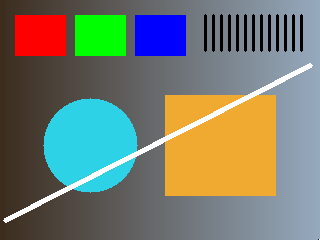

nearest: 축소 shape=(60, 80, 3), 확대 shape=(240, 320, 3)


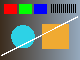

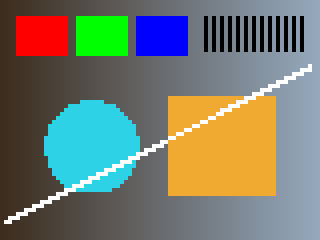

linear: 축소 shape=(60, 80, 3), 확대 shape=(240, 320, 3)


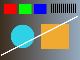

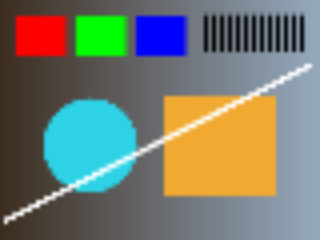

area: 축소 shape=(60, 80, 3), 확대 shape=(240, 320, 3)


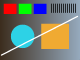

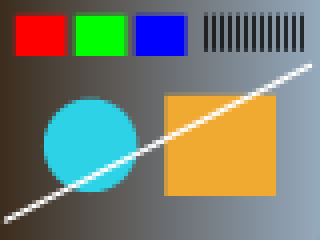

검증: 세 보간법의 축소·확대 크기 및 CSV의 왕복 MSE 일치


In [3]:
results = pd.read_csv("outputs/p02_interpolation.csv")
display(results)
print("원본")
display(Image(filename=str(exercise / "data/scene.png")))
for item in methods:
    name = item["name"]
    small_read = cv2.imread(f"outputs/p02_{name}_small.png")
    large_read = cv2.imread(f"outputs/p02_{name}_large.png")
    print(f"{name}: 축소 shape={small_read.shape}, 확대 shape={large_read.shape}")
    display(Image(filename=str(exercise / f"outputs/p02_{name}_small.png")))
    display(Image(filename=str(exercise / f"outputs/p02_{name}_large.png")))
    assert small_read.shape == (60, 80, 3)
    assert large_read.shape == image.shape == (240, 320, 3)
    mse_read = np.mean((image.astype(np.float32) - large_read.astype(np.float32)) ** 2)
    recorded = results.loc[results["method"] == name, "roundtrip_mse"].iloc[0]
    assert abs(float(mse_read) - recorded) <= 0.000051
assert results["method"].tolist() == ["nearest", "linear", "area"]
assert (results["width"] == 80).all() and (results["height"] == 60).all()
print("검증: 세 보간법의 축소·확대 크기 및 CSV의 왕복 MSE 일치")

## 3. 결과 해석

표는 원본 코드의 NEAREST → LINEAR → AREA 순서로 표시합니다. 같은 입력과 크기에서 생긴 수치 차이와 이미지 경계·문자·색상 패치의 변화를 관찰할 수 있습니다. 특정 방식의 선택이나 우수성에 대한 결론은 포함하지 않습니다.

출력 파일은 실행 중 생성되며, 이 노트북에는 실행 출력과 이미지가 포함되어 있습니다.

In [4]:
os.chdir(notebook_start)  # 노트북 실행 전 작업 폴더로 돌아갑니다.